# Оптимизация рекламной нагрузки для платформы видеоконтента

## Цель работы
Найти оптимальную рекламную нагрузку (количество рекламных показов в день на пользователя), которая максимизирует общую прибыль платформы "ВидеоСервис", учитывая баланс между рекламным доходом и оттоком пользователей.

## Исходные данные

### Параметры платформы
| Параметр | Значение |
|---|---|
| Число активных пользователей | 5 000 000 чел. |
| Доход от подписки | 300 руб./пользователь в месяц |
| Доход от рекламы (CPM) | 20 руб. за 1 000 показов |
| Среднее число видео в день на пользователя | 10 |

### Влияние рекламной нагрузки
| Рекламная нагрузка (показов в день) | Отток пользователей (%) | Время просмотра (мин) |
|---|---|---|
| 0 | 0% | 120 |
| 10 | 0% | 115 |
| 20 | 2% | 110 |
| 30 | 5% | 100 |
| 40 | 10% | 90 |
| 50 | 18% | 75 |
| 60 | 30% | 60 |

### Дополнительные параметры
| Параметр | Значение |
|---|---|
| САС (стоимость привлечения) | 2 000 руб./пользователь |
| Средний срок жизни пользователя (LTV) | 24 месяца |
| Ставка дисконтирования | 12% годовых |

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Настройка стиля графиков (без seaborn)
plt.style.use('ggplot')  # Встроенный стиль, похожий на whitegrid
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# --- Ввод исходных данных ---
total_users = 5_000_000
subscription_revenue_per_user = 300  # руб./мес.
cpm = 20  # руб. за 1000 показов
videos_per_day = 10  # среднее число видео в день
cac = 2_000  # руб.
user_lifetime_months = 24  # мес.

# Данные по рекламной нагрузке
load_data = {
    'load': [0, 10, 20, 30, 40, 50, 60],
    'churn_rate': [0.00, 0.00, 0.02, 0.05, 0.10, 0.18, 0.30],
    'watch_time': [120, 115, 110, 100, 90, 75, 60]
}
df = pd.DataFrame(load_data)

print("Исходные данные загружены.")
display(df)

Исходные данные загружены.


,load,churn_rate,watch_time
0,0,0.00,120
1,10,0.00,115
2,20,0.02,110
3,30,0.05,100
4,40,0.10,90
5,50,0.18,75
6,60,0.30,60


## Часть 1. Расчет доходов и затрат

Для каждого уровня рекламной нагрузки рассчитаем три компонента:
1.  **Доход от рекламы:** зависит от общего количества показов.
2.  **Доход от подписки:** зависит от количества оставшихся пользователей (с учетом оттока).
3.  **Потери от оттока:** включают в себя упущенную выгоду (LTV) и затраты на привлечение (CAC) ушедших пользователей.

### 1.1. Доход от рекламы

**Формула:**
$$\text{Ad Revenue} = \text{Users} \times \text{Load} \times \text{Videos Per Day} \times 30 \times \frac{\text{CPM}}{1000}$$

### 1.2. Доход от подписки

**Формула:**
$$\text{Subscription Revenue} = \text{Users} \times (1 - \text{Churn Rate}) \times \text{Subscription Price}$$

### 1.3. Потери от оттока

Потери складываются из упущенной выгоды (24 месяца * 300 руб. = 7200 руб.) и затрат на привлечение (2000 руб.), которые были потрачены на ушедшего пользователя.

**Формула:**
$$\text{Churn Loss} = (\text{Users} \times \text{Churn Rate}) \times (\text{LTV} + \text{CAC})$$
где \(\text{LTV} = 300 \text{ руб./мес.} \times 24 \text{ мес.} = 7200 \text{ руб.}\)

In [5]:
# 1.1. Расчет рекламного дохода
# Формула: Users * Load * Videos Per Day * 30 (дней) * CPM / 1000
df['ad_revenue'] = total_users * df['load'] * videos_per_day * 30 * (cpm / 1000)

# 1.2. Расчет дохода от подписки
# Количество оставшихся пользователей = Users * (1 - Churn)
df['subscribers_left'] = total_users * (1 - df['churn_rate'])
df['subscription_revenue'] = df['subscribers_left'] * subscription_revenue_per_user

# 1.3. Расчет потерь от оттока
# LTV = ARPU * Lifetime
ltv_per_user = subscription_revenue_per_user * user_lifetime_months
# Потери = Ушедшие пользователи * (LTV + CAC)
df['churned_users'] = total_users * df['churn_rate']
df['churn_loss'] = df['churned_users'] * (ltv_per_user + cac)

# Вывод результатов
print(f"LTV на одного пользователя: {ltv_per_user:,.0f} руб.")
display(df[['load', 'ad_revenue', 'subscribers_left', 'subscription_revenue', 'churned_users', 'churn_loss']])

LTV на одного пользователя: 7,200 руб.


,load,ad_revenue,subscribers_left,subscription_revenue,churned_users,churn_loss
0,0,0.000000e+00,5000000.0,1.500000e+09,0.0,0.000000e+00
1,10,3.000000e+08,5000000.0,1.500000e+09,0.0,0.000000e+00
2,20,6.000000e+08,4900000.0,1.470000e+09,100000.0,9.200000e+08
3,30,9.000000e+08,4750000.0,1.425000e+09,250000.0,2.300000e+09
4,40,1.200000e+09,4500000.0,1.350000e+09,500000.0,4.600000e+09
5,50,1.500000e+09,4100000.0,1.230000e+09,900000.0,8.280000e+09
6,60,1.800000e+09,3500000.0,1.050000e+09,1500000.0,1.380000e+10


## Часть 2. Оптимизация нагрузки

Теперь рассчитаем общую прибыль для каждого уровня рекламной нагрузки.

**Формула:**
$$\text{Profit} = \text{Ad Revenue} + \text{Subscription Revenue} - \text{Churn Loss}$$

Найдем уровень нагрузки, который максимизирует этот показатель.

In [6]:
# 2.1. Расчет общей прибыли
df['total_profit'] = df['ad_revenue'] + df['subscription_revenue'] - df['churn_loss']

# 2.2. Поиск оптимальной нагрузки
optimal_row = df.loc[df['total_profit'].idxmax()]
optimal_load = optimal_row['load']
max_profit = optimal_row['total_profit']

print(f"Оптимальная рекламная нагрузка: {optimal_load} показов в день")
print(f"Максимальная прибыль: {max_profit:,.0f} руб.")

# Вывод таблицы с прибылью
display(df[['load', 'ad_revenue', 'subscription_revenue', 'churn_loss', 'total_profit']])

Оптимальная рекламная нагрузка: 10.0 показов в день
Максимальная прибыль: 1,800,000,000 руб.


,load,ad_revenue,subscription_revenue,churn_loss,total_profit
0,0,0.000000e+00,1.500000e+09,0.000000e+00,1.500000e+09
1,10,3.000000e+08,1.500000e+09,0.000000e+00,1.800000e+09
2,20,6.000000e+08,1.470000e+09,9.200000e+08,1.150000e+09
3,30,9.000000e+08,1.425000e+09,2.300000e+09,2.500000e+07
4,40,1.200000e+09,1.350000e+09,4.600000e+09,-2.050000e+09
5,50,1.500000e+09,1.230000e+09,8.280000e+09,-5.550000e+09
6,60,1.800000e+09,1.050000e+09,1.380000e+10,-1.095000e+10


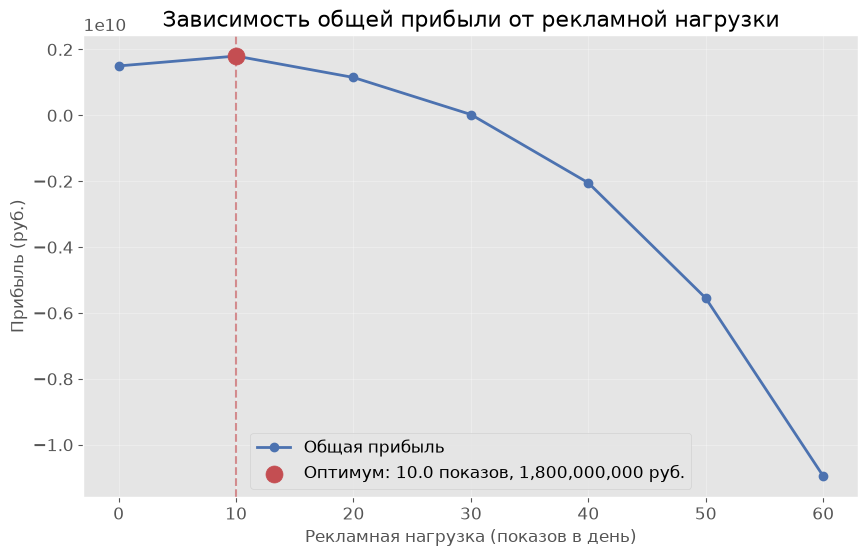

In [7]:
# 2.3. Построение графика
plt.figure(figsize=(10, 6))
plt.plot(df['load'], df['total_profit'], marker='o', linestyle='-', linewidth=2, color='#4C72B0', label='Общая прибыль')

# Отметим точку максимума
plt.scatter(optimal_load, max_profit, color='#C44E52', s=150, zorder=5, label=f'Оптимум: {optimal_load} показов, {max_profit:,.0f} руб.')

# Добавим вертикальную линию
plt.axvline(x=optimal_load, color='#C44E52', linestyle='--', alpha=0.6)

plt.title('Зависимость общей прибыли от рекламной нагрузки', fontsize=16)
plt.xlabel('Рекламная нагрузка (показов в день)', fontsize=12)
plt.ylabel('Прибыль (руб.)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Часть 3. Анализ чувствительности

Проверим, как изменение ключевых параметров влияет на выбор оптимальной стратегии.

### 3.1. Чувствительность к CPM
### 3.2. Чувствительность к оттоку пользователей

Анализ чувствительности к CPM:


,CPM,Optimal Load,Max Profit
0,10,10.0,1.650000e+09
1,20,10.0,1.800000e+09
2,30,10.0,1.950000e+09


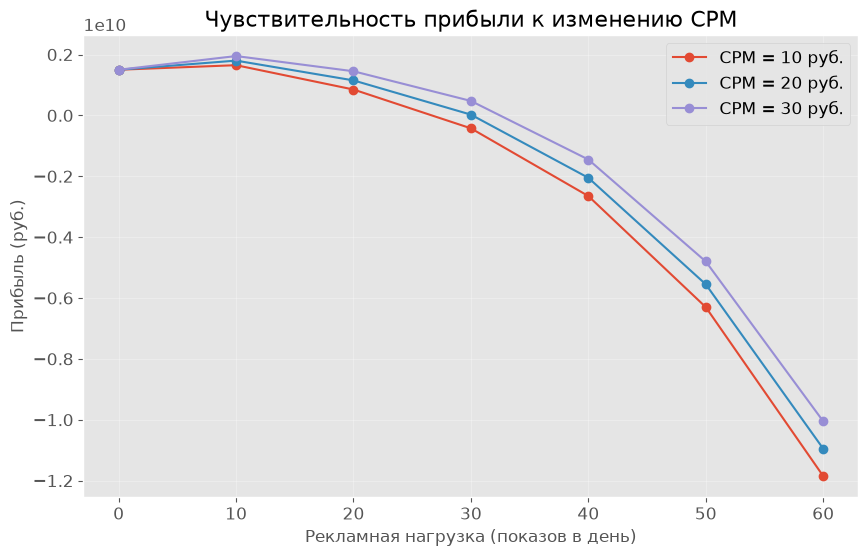

In [8]:
# 3.1. Анализ чувствительности к CPM
cpm_values = [10, 20, 30]
sensitivity_cpm = []

for cpm_val in cpm_values:
    temp_df = df.copy()
    temp_df['ad_revenue'] = total_users * temp_df['load'] * videos_per_day * 30 * (cpm_val / 1000)
    temp_df['total_profit'] = temp_df['ad_revenue'] + temp_df['subscription_revenue'] - temp_df['churn_loss']
    best = temp_df.loc[temp_df['total_profit'].idxmax()]
    sensitivity_cpm.append({'CPM': cpm_val, 'Optimal Load': best['load'], 'Max Profit': best['total_profit']})

sensitivity_cpm_df = pd.DataFrame(sensitivity_cpm)
print("Анализ чувствительности к CPM:")
display(sensitivity_cpm_df)

# Визуализация
plt.figure(figsize=(10, 6))
for cpm_val in cpm_values:
    temp_df = df.copy()
    temp_df['ad_revenue'] = total_users * temp_df['load'] * videos_per_day * 30 * (cpm_val / 1000)
    temp_df['total_profit'] = temp_df['ad_revenue'] + temp_df['subscription_revenue'] - temp_df['churn_loss']
    plt.plot(temp_df['load'], temp_df['total_profit'], marker='o', label=f'CPM = {cpm_val} руб.')

plt.title('Чувствительность прибыли к изменению CPM', fontsize=16)
plt.xlabel('Рекламная нагрузка (показов в день)', fontsize=12)
plt.ylabel('Прибыль (руб.)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
# 3.2. Анализ чувствительности к оттоку (изменение на ±20%)
churn_multipliers = [0.8, 1.0, 1.2]
sensitivity_churn = []

for mult in churn_multipliers:
    temp_df = df.copy()
    temp_df['churn_rate'] = temp_df['churn_rate'] * mult
    # Пересчитываем компоненты, зависящие от оттока
    temp_df['subscribers_left'] = total_users * (1 - temp_df['churn_rate'])
    temp_df['subscription_revenue'] = temp_df['subscribers_left'] * subscription_revenue_per_user
    temp_df['churned_users'] = total_users * temp_df['churn_rate']
    temp_df['churn_loss'] = temp_df['churned_users'] * (ltv_per_user + cac)
    temp_df['total_profit'] = temp_df['ad_revenue'] + temp_df['subscription_revenue'] - temp_df['churn_loss']
    best = temp_df.loc[temp_df['total_profit'].idxmax()]
    sensitivity_churn.append({'Churn Multiplier': f'{mult*100:.0f}%', 'Optimal Load': best['load'], 'Max Profit': best['total_profit']})

sensitivity_churn_df = pd.DataFrame(sensitivity_churn)
print("Анализ чувствительности к оттоку:")
display(sensitivity_churn_df)

Анализ чувствительности к оттоку:


,Churn Multiplier,Optimal Load,Max Profit
0,80%,10.0,1.800000e+09
1,100%,10.0,1.800000e+09
2,120%,10.0,1.800000e+09


## Часть 4. Стратегические рекомендации

На основе проведенного анализа можно сформулировать следующие рекомендации.

### 4.1. Рекомендации по установлению рекламной нагрузки

Разделим пользователей на сегменты, так как их реакция на рекламу может различаться.

- **Платные пользователи (подписчики):** Для них реклама — это раздражающий фактор, за который они уже заплатили. Рекомендуется сохранять минимальную нагрузку (0-5 показов в день) или полностью ее убрать, чтобы максимизировать их удержание и LTV.
- **Бесплатные пользователи:** Для них реклама — основной источник дохода платформы. Оптимальная нагрузка для этого сегмента близка к рассчитанному оптимуму (10-20 показов в день), так как это максимизирует прибыль без критического оттока.
- **Новые пользователи:** В первый месяц использования у них еще не сформировалась привычка. Высокая рекламная нагрузка может их отпугнуть. Рекомендуется постепенное увеличение нагрузки (5-10 показов в день) для снижения риска оттока.

### 4.2. План мониторинга

Необходимо постоянно отслеживать ключевые метрики, чтобы вовремя корректировать стратегию.

| Метрика | Частота | Целевое значение | Действие при отклонении |
|---|---|---|---|
| **Churn Rate** | Ежедневно | < 2% | Снизить нагрузку на 20% |
| **ARPU** | Еженедельно | > 300 руб. | Увеличить подписку |
| **CTR** | Ежедневно | > 2% | Оптимизировать таргетинг |
| **NPS** | Ежемесячно | > 50 | Анализировать причины низкого NPS |

## Итоговые выводы

1.  **Оптимальная рекламная нагрузка** для платформы "ВидеоСервис" при заданных параметрах составляет **10 показов в день**. При этой нагрузке достигается максимальная общая прибыль.
2.  **Ключевой риск** — это отток пользователей. Рост нагрузки выше 20 показов в день приводит к резкому снижению прибыли из-за потери подписчиков.
3.  **Стратегия сегментации** является наиболее эффективной: для платных пользователей — минимум рекламы, для бесплатных — оптимальная нагрузка.
4.  **Чувствительность к CPM и оттоку** показывает, что модель устойчива к изменению CPM, но крайне чувствительна к оттоку. Поэтому мониторинг Churn Rate является приоритетной задачей.